In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

[  88.27275507 -116.25716066]
1053.4444444444443


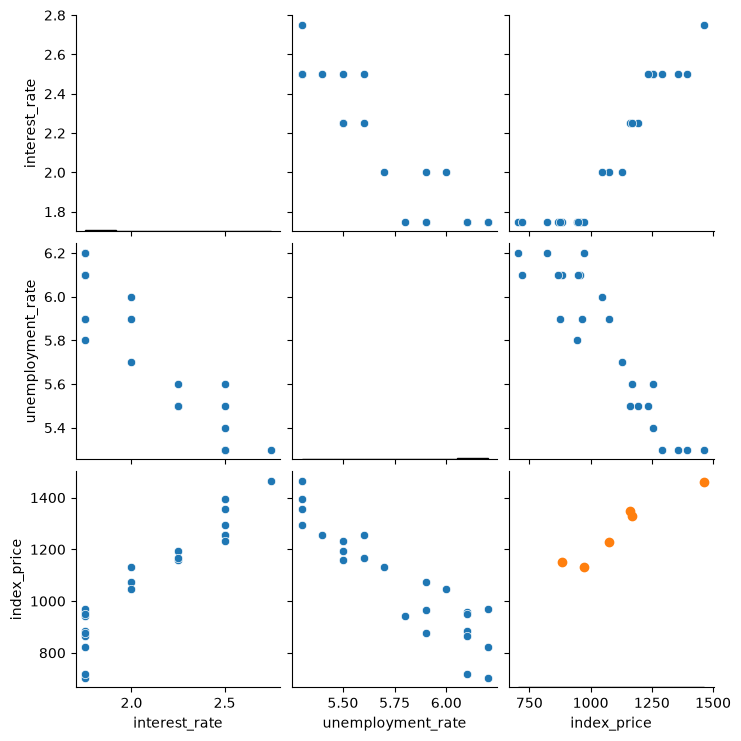

In [ ]:
# Reading the dataset
df = pd.read_csv(r"C:/Users/shari/Downloads/DataScience Bootcamp/Python/FeatureEngineering/economic_index.csv")

df.drop(['Unnamed: 0','year','month'], axis=1, inplace=True)
df.head()

df.isnull().sum()

sns.pairplot(df)

df.corr()

# Dependent and Independent features
X = df[['interest_rate','unemployment_rate']]
y = df['index_price']

# Train Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

#Standardization of train and test data

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Applying Linear Regression

from sklearn.linear_model import LinearRegression
reg = LinearRegression(n_jobs=-1)
reg.fit(X_train, y_train)

y_pred_train = reg.predict(X_train)
print(reg.coef_)
print(reg.intercept_)

# #prediction
y_pred = reg.predict(X_test)





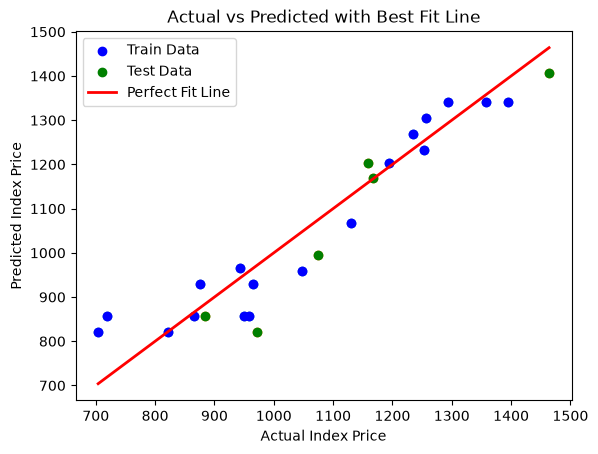

In [35]:
plt.scatter(y_train, y_pred_train)
plt.scatter(y_test, y_pred)
min_val = min(y_train.min(), y_test.min())
max_val = max(y_train.max(), y_test.max())

plt.scatter(y_train, y_pred_train, color="blue", label="Train Data")
plt.scatter(y_test, y_pred, color="green", label="Test Data")

# Best fit (perfect prediction) line
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linewidth=2, label="Perfect Fit Line")

plt.xlabel("Actual Index Price")
plt.ylabel("Predicted Index Price")
plt.title("Actual vs Predicted with Best Fit Line")
plt.legend()
plt.show()



# plt.plot(y_test, y_pred)

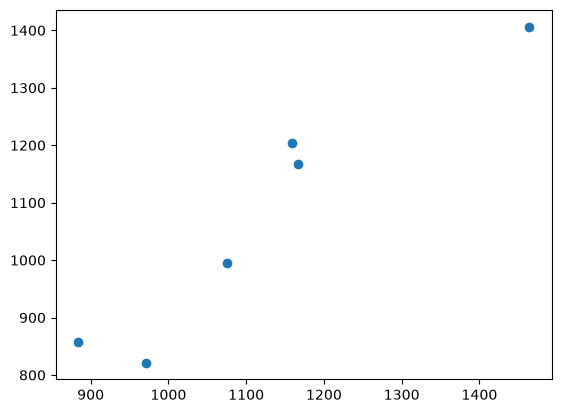

In [37]:
# # Prediction plot
plt.scatter(y_test, y_pred)

In [38]:
# Performance

from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
print(mse)
print(mae)
print(rmse)

5793.762887712569
59.935781523235484
76.11677139574805


In [43]:
from sklearn.metrics import r2_score
score = r2_score(y_test,y_pred)
print(score)

adjusted_r2_score = 1 - ((1 - score)*(len(y_test) - 1))/(len(y_test) - X_test.shape[1] - 1)
print(adjusted_r2_score)

0.8278978091457145
0.7131630152428576


In [46]:
# using cross validation

from sklearn.model_selection import cross_val_score

validation_score = cross_val_score(reg, X_train, y_train, scoring= "neg_mean_squared_error", cv=3)
np.mean(validation_score)

np.float64(-5914.828180162386)

In [49]:
import statsmodels.api as sm

models = sm.OLS(y_train, X_train).fit()
print(models.summary())

prediction = models.predict(X_test)

                                 OLS Regression Results                                
Dep. Variable:            index_price   R-squared (uncentered):                   0.035
Model:                            OLS   Adj. R-squared (uncentered):             -0.086
Method:                 Least Squares   F-statistic:                             0.2880
Date:                Wed, 07 Oct 2026   Prob (F-statistic):                       0.754
Time:                        14:19:52   Log-Likelihood:                         -150.85
No. Observations:                  18   AIC:                                      305.7
Df Residuals:                      16   BIC:                                      307.5
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64


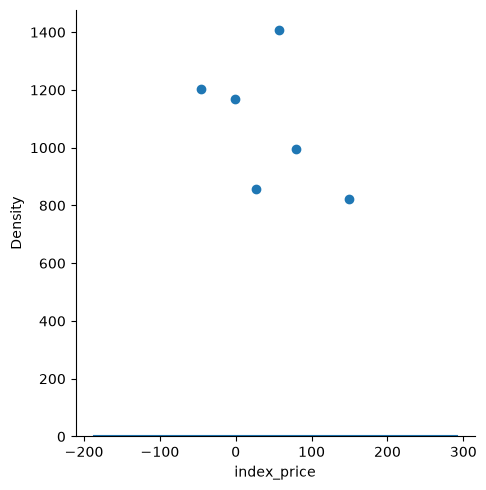

In [57]:
residual = y_test - y_pred
print(residual)

sns.displot(residual, kind= "kde")

# sns.scatterplot(residual, y_pred)

plt.scatter(residual, y_pred)